```markdown
# Predictive Maintenance and Sensorless Drive Diagnosis

This repository/notebook contains a comprehensive machine learning analysis tackling two distinct and critical engineering classification tasks:

1. **Sensorless Drive Diagnosis**: Diagnosing various operating states of an electric motor drive using 48 features derived from phase currents. This is a balanced, 11-class multi-class classification problem.
2. **AI4I Predictive Maintenance (Machine Failure)**: Predicting industrial machine failures based on 5 technical process features. This is a highly imbalanced binary classification problem (failures represent ~3.4% of the dataset), where we aim to maximize both reliability and recall to prevent costly unplanned downtime.

### Notebook Overview
- **Exploratory Data Analysis & Preprocessing**
- **Model Training & Comparison**: Implementing Decision Trees, Random Forests, and Gradient Boosting Classifiers.
- **Hyperparameter Optimization**: Using Grid Search with Stratified Cross-Validation.
- **Performance Evaluation**: Advanced evaluation metrics (F1-score, Precision-Recall tradeoffs, and Confusion Matrices).
```

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00325/Sensorless_drive_diagnosis.txt"

data = pd.read_csv(url, sep=r'\s+', header=None)

X = data.iloc[:, :-1]
y = data.iloc[:, -1].astype(int)

print('Shape of X:', X.shape)
print('Number of classes:', y.nunique())
display(X.head())
print('Class counts:')
print(y.value_counts().sort_index())

Shape of X: (58509, 48)
Number of classes: 11


,0,1,2,3,4,5,6,7,8,9,...,38,39,40,41,42,43,44,45,46,47
0,-3.014600e-07,8.260300e-06,-0.000012,-0.000002,-1.438600e-06,-0.000021,0.031718,0.031710,0.031721,-0.032963,...,6.0168,-0.63308,2.9646,8.1198,-1.4961,-1.4961,-1.4961,-1.4996,-1.4996,-1.4996
1,2.913200e-06,-5.247700e-06,0.000003,-0.000006,2.778900e-06,-0.000004,0.030804,0.030810,0.030806,-0.033520,...,3.6048,-0.59314,7.6252,6.1690,-1.4967,-1.4967,-1.4967,-1.5005,-1.5005,-1.5005
2,-2.951700e-06,-3.184000e-06,-0.000016,-0.000001,-1.575300e-06,0.000017,0.032877,0.032880,0.032896,-0.029834,...,5.8007,-0.63252,2.7784,5.3017,-1.4983,-1.4983,-1.4982,-1.4985,-1.4985,-1.4985
3,-1.322600e-06,8.820100e-06,-0.000016,-0.000005,-7.282900e-07,0.000004,0.029410,0.029401,0.029417,-0.030156,...,23.3960,-0.62289,6.5534,6.2606,-1.4963,-1.4963,-1.4963,-1.4975,-1.4975,-1.4976
4,-6.836600e-08,5.666300e-07,-0.000026,-0.000006,-7.940600e-07,0.000013,0.030119,0.030119,0.030145,-0.031393,...,5.0582,-0.63010,4.5155,9.5231,-1.4958,-1.4958,-1.4958,-1.4959,-1.4959,-1.4959


Class counts:
48
1     5319
2     5319
3     5319
4     5319
5     5319
6     5319
7     5319
8     5319
9     5319
10    5319
11    5319
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print('Training samples:', len(X_train))
print('Test samples:', len(X_test))

Training samples: 40956
Test samples: 17553


In [ ]:
results = []

for n in [5, 10, 25]:

    models = {
        'Random Forest':     RandomForestClassifier(n_estimators=n, random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=n, random_state=42)
    }

    for name, model in models.items():

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        results.append({
            'Model': name,
            'n_estimators': n,
            'Train Accuracy': accuracy_score(y_train, train_pred),
            'Test Accuracy': accuracy_score(y_test, test_pred),
            'Precision': precision_score(y_test, test_pred, average='macro'),
            'Recall': recall_score(y_test, test_pred, average='macro'),
            'F1-score': f1_score(y_test, test_pred, average='macro')
        })

        print(f'finished: {name} with n_estimators = {n}')

results_t1 = pd.DataFrame(results)

finished: Random Forest with n_estimators = 5
finished: Gradient Boosting with n_estimators = 5
finished: Random Forest with n_estimators = 10
finished: Gradient Boosting with n_estimators = 10
finished: Random Forest with n_estimators = 25
finished: Gradient Boosting with n_estimators = 25


In [ ]:
results_t1['Train-Test Gap'] = results_t1['Train Accuracy'] - results_t1['Test Accuracy']

display(results_t1.round(4))

,Model,n_estimators,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,Train-Test Gap
0,Random Forest,5,0.9996,0.9956,0.9956,0.9956,0.9956,0.0040
1,Gradient Boosting,5,0.8659,0.8638,0.8710,0.8638,0.8638,0.0020
2,Random Forest,10,1.0000,0.9977,0.9977,0.9977,0.9977,0.0023
3,Gradient Boosting,10,0.8949,0.8916,0.8944,0.8916,0.8918,0.0032
4,Random Forest,25,1.0000,0.9985,0.9985,0.9985,0.9985,0.0015
5,Gradient Boosting,25,0.9608,0.9578,0.9580,0.9578,0.9579,0.0030


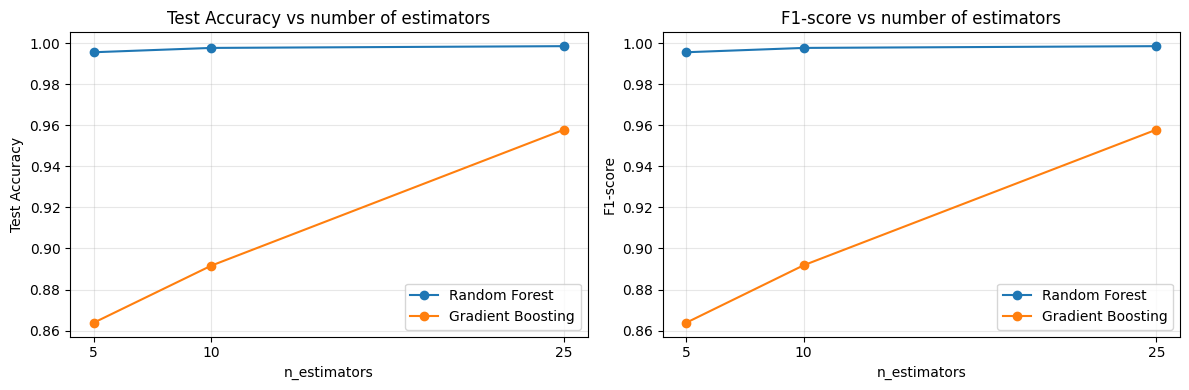

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ['Test Accuracy', 'F1-score']):

    for name in results_t1['Model'].unique():
        subset = results_t1[results_t1['Model'] == name]
        ax.plot(subset['n_estimators'], subset[metric], 'o-', label=name)

    ax.set_xlabel('n_estimators')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} vs number of estimators')
    ax.set_xticks([5, 10, 25])
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_rf_n = int(results_t1[results_t1['Model'] == 'Random Forest']
                .sort_values('Test Accuracy').iloc[-1]['n_estimators'])

best_gb_n = int(results_t1[results_t1['Model'] == 'Gradient Boosting']
                .sort_values('Test Accuracy').iloc[-1]['n_estimators'])

print('Best Random Forest     : n_estimators =', best_rf_n)
print('Best Gradient Boosting : n_estimators =', best_gb_n)

best_rf = RandomForestClassifier(n_estimators=best_rf_n, random_state=42).fit(X_train, y_train)
best_gb = GradientBoostingClassifier(n_estimators=best_gb_n, random_state=42).fit(X_train, y_train)

Best Random Forest     : n_estimators = 25
Best Gradient Boosting : n_estimators = 25


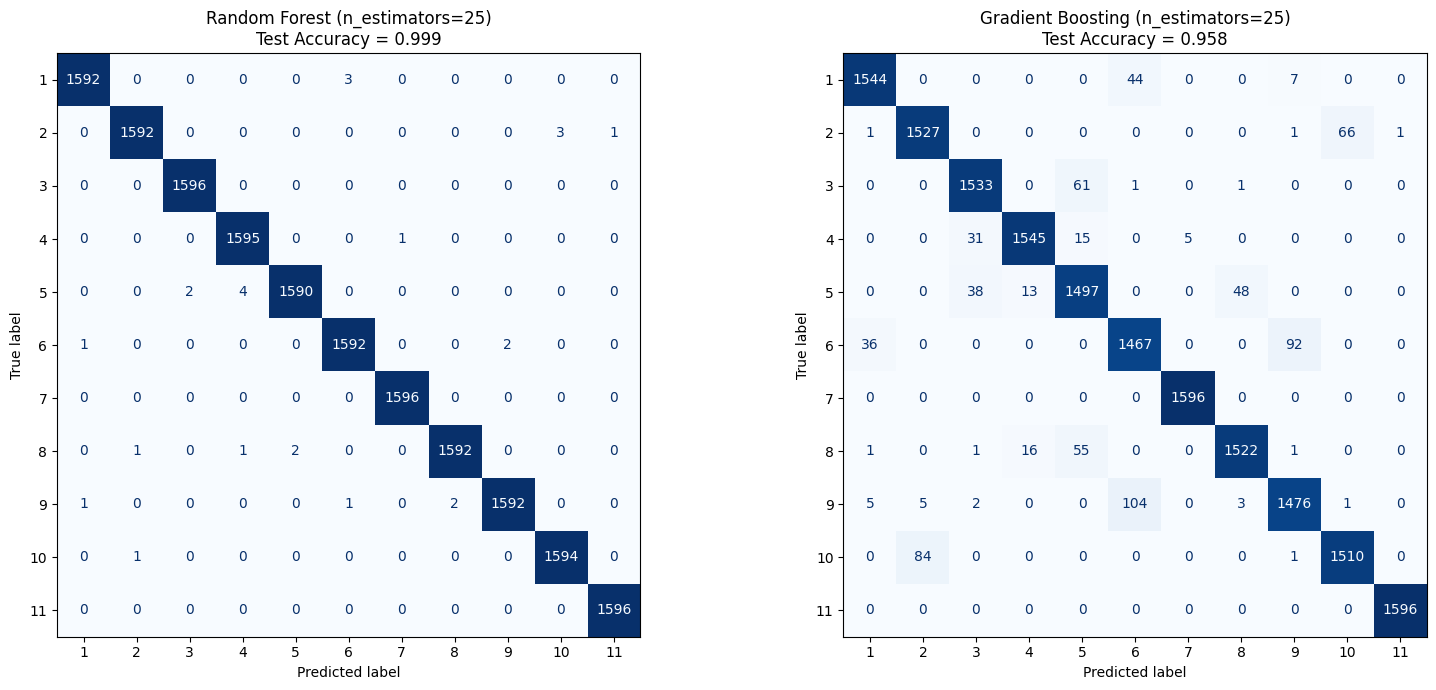

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model, title in [(axes[0], best_rf, f'Random Forest (n_estimators={best_rf_n})'),
                         (axes[1], best_gb, f'Gradient Boosting (n_estimators={best_gb_n})')]:

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, cmap='Blues', colorbar=False, values_format='d', ax=ax
    )

    ax.set_title(f'{title}\nTest Accuracy = {accuracy_score(y_test, y_pred):.3f}')
    ax.grid(False)

plt.tight_layout()
plt.show()

In [ ]:
print('Random Forest\n')
print(classification_report(y_test, best_rf.predict(X_test), digits=3, zero_division=0))

print('\nGradient Boosting\n')
print(classification_report(y_test, best_gb.predict(X_test), digits=3, zero_division=0))

Random Forest

              precision    recall  f1-score   support

           1      0.999     0.998     0.998      1595
           2      0.999     0.997     0.998      1596
           3      0.999     1.000     0.999      1596
           4      0.997     0.999     0.998      1596
           5      0.999     0.996     0.997      1596
           6      0.997     0.998     0.998      1595
           7      0.999     1.000     1.000      1596
           8      0.999     0.997     0.998      1596
           9      0.999     0.997     0.998      1596
          10      0.998     0.999     0.999      1595
          11      0.999     1.000     1.000      1596

    accuracy                          0.999     17553
   macro avg      0.999     0.999     0.999     17553
weighted avg      0.999     0.999     0.999     17553


Gradient Boosting

              precision    recall  f1-score   support

           1      0.973     0.968     0.970      1595
           2      0.945     0.957     0.951

In [ ]:
url2 = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"

df = pd.read_csv(url2)

features = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

X2 = df[features]
y2 = df['Machine failure']

print('Shape of X2:', X2.shape)
print('Missing values:', X2.isna().sum().sum())
display(X2.head())
print('Class counts:')
print(y2.value_counts())

Shape of X2: (10000, 5)
Missing values: 0


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9


Class counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [ ]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.30, random_state=42, stratify=y2
)

print('Training samples:', len(X2_train), '| failures:', y2_train.sum())
print('Test samples:', len(X2_test), '| failures:', y2_test.sum())

Training samples: 7000 | failures: 237
Test samples: 3000 | failures: 102


In [ ]:
tree = DecisionTreeClassifier(random_state=42)

tree.fit(X2_train, y2_train)

print('Tree depth:', tree.get_depth())
print('Number of leaves:', tree.get_n_leaves())
print(f'Train accuracy: {accuracy_score(y2_train, tree.predict(X2_train)):.3f}')
print(f'Test accuracy:  {accuracy_score(y2_test, tree.predict(X2_test)):.3f}')

Tree depth: 19
Number of leaves: 147
Train accuracy: 1.000
Test accuracy:  0.974


In [ ]:
parameter = {
    'criterion': ['gini'],
    'max_depth': [2, 3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_features': [None, 'sqrt']
}

tree_pruned = DecisionTreeClassifier(random_state=42)

m1 = GridSearchCV(tree_pruned, param_grid=parameter, cv=5, scoring='f1', n_jobs=-1)

m1.fit(X2_train, y2_train)

print('Best parameters:', m1.best_params_)
print(f'Best cross-validated F1: {m1.best_score_:.3f}')

Best parameters: {'criterion': 'gini', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 5}
Best cross-validated F1: 0.681


In [ ]:
tree_pruned = m1.best_estimator_

print('Tree depth:', tree_pruned.get_depth())
print('Number of leaves:', tree_pruned.get_n_leaves())
print(f'Train accuracy: {accuracy_score(y2_train, tree_pruned.predict(X2_train)):.3f}')
print(f'Test accuracy:  {accuracy_score(y2_test, tree_pruned.predict(X2_test)):.3f}')

Tree depth: 10
Number of leaves: 58
Train accuracy: 0.989
Test accuracy:  0.981


In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X2_train, y2_train)

gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X2_train, y2_train)

print(f'Random Forest test accuracy:     {accuracy_score(y2_test, rf.predict(X2_test)):.3f}')
print(f'Gradient Boosting test accuracy: {accuracy_score(y2_test, gb.predict(X2_test)):.3f}')

Random Forest test accuracy:     0.984
Gradient Boosting test accuracy: 0.983


In [ ]:
models = {
    'Decision Tree': tree,
    'Decision Tree (pre-pruned)': tree_pruned,
    'Random Forest': rf,
    'Gradient Boosting': gb
}

results = []

for name, model in models.items():

    train_pred = model.predict(X2_train)
    test_pred = model.predict(X2_test)

    train_acc = accuracy_score(y2_train, train_pred)
    test_acc = accuracy_score(y2_test, test_pred)

    results.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Train-Test Gap': train_acc - test_acc,
        'Precision': precision_score(y2_test, test_pred, zero_division=0),
        'Recall': recall_score(y2_test, test_pred, zero_division=0),
        'F1-score': f1_score(y2_test, test_pred, zero_division=0)
    })

results_t2 = pd.DataFrame(results)

display(results_t2.round(4))


,Model,Train Accuracy,Test Accuracy,Train-Test Gap,Precision,Recall,F1-score
0,Decision Tree,1.0000,0.9740,0.0260,0.6111,0.6471,0.6286
1,Decision Tree (pre-pruned),0.9937,0.9790,0.0147,0.7191,0.6275,0.6702
2,Random Forest,1.0000,0.9843,0.0157,0.8667,0.6373,0.7345
3,Gradient Boosting,0.9909,0.9827,0.0082,0.8676,0.5784,0.6941


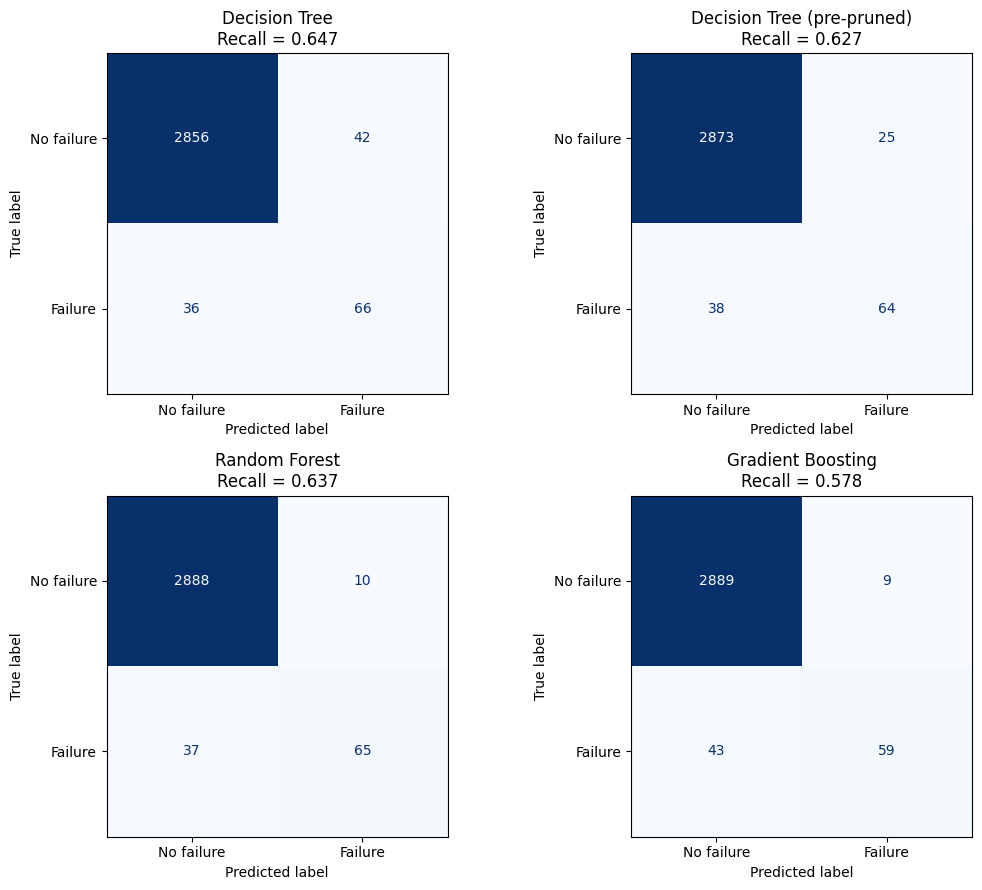

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model) in zip(axes.flatten(), models.items()):

    y_pred = model.predict(X2_test)

    ConfusionMatrixDisplay.from_predictions(
        y2_test, y_pred, display_labels=['No failure', 'Failure'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax
    )

    ax.set_title(f'{name}\nRecall = {recall_score(y2_test, y_pred, zero_division=0):.3f}')
    ax.grid(False)

plt.tight_layout()
plt.show()

In [ ]:
print(f"{'Model':<28}{'Failures':>10}{'Caught':>9}{'Missed':>9}{'False alarms':>14}")

for name, model in models.items():

    tn, fp, fn, tp = confusion_matrix(y2_test, model.predict(X2_test)).ravel()

    print(f'{name:<28}{tp + fn:>10}{tp:>9}{fn:>9}{fp:>14}')

Model                         Failures   Caught   Missed  False alarms
Decision Tree                      102       66       36            42
Decision Tree (pre-pruned)         102       64       38            25
Random Forest                      102       65       37            10
Gradient Boosting                  102       59       43             9


```markdown
## Advanced Model Optimization and Feature Importance
To push our predictive maintenance model further, let's explore hyperparameter tuning for our top-performing ensemble method (Random Forest) with a focus on mitigating class imbalance (using `class_weight='balanced'`), and visualize the features that play the most critical role in predicting machine failure.
```

In [6]:
# Load dataset, split, and run hyperparameter tuning for Random Forest to improve recall
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Ensure data is loaded and split
url2 = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
df = pd.read_csv(url2)

features = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

X2 = df[features]
y2 = df['Machine failure']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.30, random_state=42, stratify=y2
)

rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 10, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample', None]
}

optimal_rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

optimal_rf_search.fit(X2_train, y2_train)
print("Best RF Parameters:", optimal_rf_search.best_params_)
print(f"Best Cross-Validated F1-Score: {optimal_rf_search.best_score_:.4f}")

Best RF Parameters: {'class_weight': None, 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 150}
Best Cross-Validated F1-Score: 0.6987


In [8]:
# Evaluate the optimized Random Forest
from sklearn.metrics import f1_score, recall_score, confusion_matrix

optimized_rf = optimal_rf_search.best_estimator_
y2_opt_pred = optimized_rf.predict(X2_test)

print("Optimized Random Forest Performance:")
print(f"Test F1-Score: {f1_score(y2_test, y2_opt_pred):.4f}")
print(f"Test Recall:   {recall_score(y2_test, y2_opt_pred):.4f}")

tn, fp, fn, tp = confusion_matrix(y2_test, y2_opt_pred).ravel()
print(f"\nFailures: {tp + fn} | Caught: {tp} | Missed: {fn} | False Alarms: {fp}")

Optimized Random Forest Performance:
Test F1-Score: 0.7263
Test Recall:   0.6373

Failures: 102 | Caught: 65 | Missed: 37 | False Alarms: 12


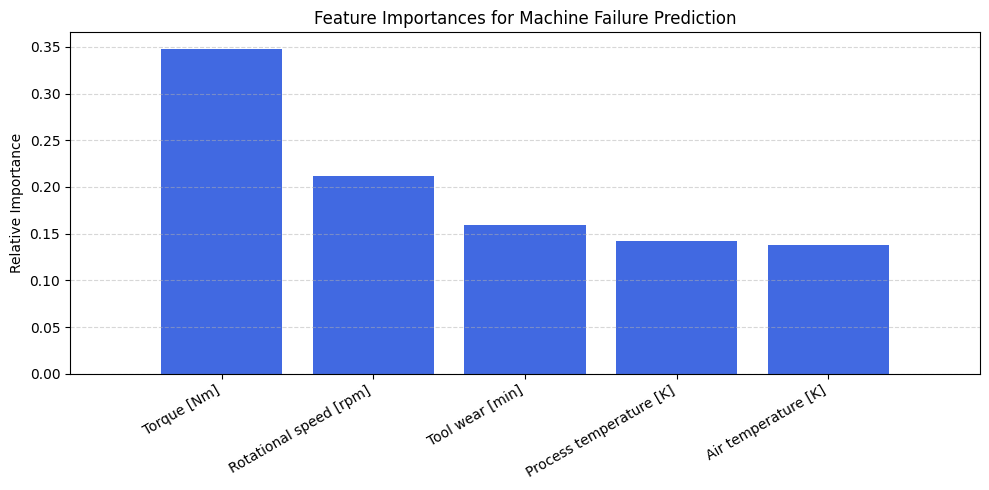

In [10]:
# Feature Importance Visualization
import numpy as np
import matplotlib.pyplot as plt

importances = optimized_rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.title("Feature Importances for Machine Failure Prediction")
plt.bar(range(X2.shape[1]), importances[indices], color="royalblue", align="center")
plt.xticks(range(X2.shape[1]), [features[i] for i in indices], rotation=30, ha='right')
plt.xlim([-1, X2.shape[1]])
plt.ylabel("Relative Importance")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()